# CodeGuard AI · Experiment 02: Clean and explore the Devign dataset (C)

**Goal:** load the Devign dataset, check it for problems, clean it, and save a clean file for Experiment 03.

> Devign is **C code**. CodeGuard AI's scanner targets Python, so this dataset is a practice run for the method, not the model the scanner uses. See `01_datasets_overview.ipynb`.

**Steps**
1. Load the raw data
2. Look at it
3. Find problems (missing values, duplicates)
4. Clean it
5. Explore it with 3 simple charts
6. Save the clean file

## What is the Devign dataset?

- It is a collection of **C functions** taken from two big open-source projects: **QEMU** (a computer emulator) and **FFmpeg** (a video/audio tool).
- Researchers looked at real security fixes. A function that was later fixed for a security bug is labelled **vulnerable (1)**. Other functions are labelled **safe (0)**.
- It was published in 2019 (Zhou et al., *Devign*, NeurIPS) and is used in Microsoft's **CodeXGLUE** benchmark as the "defect detection" task.
- The full dataset has **27,318** functions. We now use **all of it** (train + validation + test), downloaded by `scripts/download_devign.py`. An earlier version of this notebook used only 5,464 functions (validation + test).

**Columns**

| Column | Meaning |
|---|---|
| `id` | Row number in the original dataset |
| `func` | The full source code of one C function (this is our input) |
| `target` | The label: `True` = vulnerable, `False` = safe (this is what we predict) |
| `project` | Where the code came from: `qemu` or `FFmpeg` |
| `commit_id` | The Git commit the function was taken from |
| `split` | Which official CodeXGLUE split the row came from (we make our own split in Experiment 03) |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../datasets/raw/devign_raw.parquet")

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (27318, 6)


,id,func,target,project,commit_id,split
0,0,static av_cold int vdadec_init(AVCodecContext ...,False,FFmpeg,973b1a6b9070e2bf17d17568cbaf4043ce931f51,train
1,1,static int transcode(AVFormatContext **output_...,False,FFmpeg,321b2a9ded0468670b7678b7c098886930ae16b2,train
2,2,"static void v4l2_free_buffer(void *opaque, uin...",False,FFmpeg,5d5de3eba4c7890c2e8077f5b4ae569671d11cf8,train
3,4,"int av_opencl_buffer_write(cl_mem dst_cl_buf, ...",False,FFmpeg,57d77b3963ce1023eaf5ada8cba58b9379405cc8,train
4,5,"static int r3d_read_rdvo(AVFormatContext *s, A...",True,FFmpeg,aba232cfa9b193604ed98f3fa505378d006b1b3b,train


## Step 2: Look at one safe and one vulnerable function

In [2]:
safe_example = df[df["target"] == False]["func"].iloc[0]
vuln_example = df[df["target"] == True]["func"].iloc[0]

print("----- SAFE (first 300 characters) -----")
print(safe_example[:300])
print()
print("----- VULNERABLE (first 300 characters) -----")
print(vuln_example[:300])

----- SAFE (first 300 characters) -----
static av_cold int vdadec_init(AVCodecContext *avctx)

{

    VDADecoderContext *ctx = avctx->priv_data;

    struct vda_context *vda_ctx = &ctx->vda_ctx;

    OSStatus status;

    int ret;



    ctx->h264_initialized = 0;



    /* init pix_fmts of codec */

    if (!ff_h264_vda_decoder.pix_fmts)

----- VULNERABLE (first 300 characters) -----
static int r3d_read_rdvo(AVFormatContext *s, Atom *atom)

{

    R3DContext *r3d = s->priv_data;

    AVStream *st = s->streams[0];

    int i;



    r3d->video_offsets_count = (atom->size - 8) / 4;

    r3d->video_offsets = av_malloc(atom->size);

    if (!r3d->video_offsets)

        return AVERR


**Notice:** you cannot easily tell them apart by eye. The bug is often one missing check (for example, a missing `return` after an error). This is why vulnerability detection is hard, for people and for models.

## Step 3: Find problems

We check two things:

1. **Missing values:** empty cells we cannot use.
2. **Duplicates:** the same function appearing more than once. If a copy lands in the training data and another copy in the test data, the model has already "seen the answer". This is called **data leakage**, and it makes results look better than they really are.

We compare code with all spaces and line breaks removed, so two copies that differ only in formatting still count as duplicates.

In [3]:
# 1. Missing values in each column
print("Missing values:")
print(df.isnull().sum())

# 2. Duplicates (ignoring spaces and line breaks)
df["code_key"] = df["func"].str.replace(r"\s+", "", regex=True)
duplicates = df[df["code_key"].duplicated(keep=False)]

print()
print("Rows that are part of a duplicate group:", len(duplicates))
duplicates[["id", "target", "project", "commit_id"]].sort_values("id")

# How many duplicate groups have conflicting labels?
dup_groups = duplicates.groupby("code_key")["target"].nunique()
print("Duplicate groups:", len(dup_groups))
print("Groups with conflicting labels:", (dup_groups > 1).sum())

Missing values:
id           0
func         0
target       0
project      0
commit_id    0
split        0
dtype: int64



Rows that are part of a duplicate group: 180
Duplicate groups: 90
Groups with conflicting labels: 86


**What we found:**
- No missing values.
- **180 rows** belong to **90 duplicate groups**. In **86** of those groups the copies have **different labels** (the same code is marked both safe and vulnerable). We cannot know which label is right, so we remove **all** copies. For simplicity we also drop the 4 groups with matching labels.

**One more thing to know:** many functions share the same `commit_id`, and every function from one commit has the same label. In Experiment 03 we keep each commit entirely in either training or testing, so the model cannot cheat by recognising a commit.

In [4]:
commit_sizes = df["commit_id"].value_counts()
print("Different commits:", len(commit_sizes))
print("Commits with more than one function:", (commit_sizes > 1).sum())

labels_per_commit = df.groupby("commit_id")["target"].nunique()
print("Commits whose functions have mixed labels:", (labels_per_commit > 1).sum())

Different commits: 12316
Commits with more than one function: 3736
Commits whose functions have mixed labels: 0


## Step 4: Clean the data

1. Remove all copies of duplicated code.
2. Turn the label into a number: `0` = safe, `1` = vulnerable.
3. Add two simple size columns: number of lines and number of characters.

In [5]:
rows_before = len(df)

df = df.drop_duplicates(subset="code_key", keep=False)   # keep=False removes every copy
df["target"] = df["target"].astype(int)                  # True/False -> 1/0
df["n_lines"] = df["func"].str.count("\n") + 1
df["n_chars"] = df["func"].str.len()
df = df.drop(columns="code_key")

print("Rows before:", rows_before)
print("Rows after: ", len(df))
print("Removed:    ", rows_before - len(df))

Rows before: 27318
Rows after:  27138
Removed:     180


## Step 5: Explore the clean data

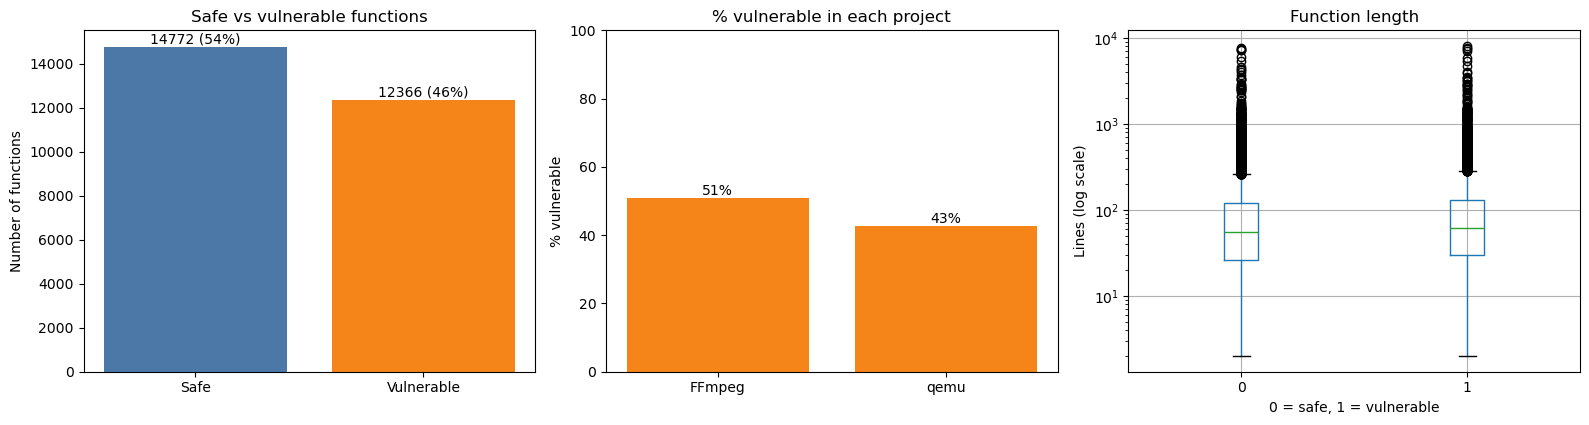

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Chart 1: how many safe vs vulnerable
counts = df["target"].map({0: "Safe", 1: "Vulnerable"}).value_counts()
axes[0].bar(counts.index, counts.values, color=["#4C78A8", "#F58518"])
axes[0].set_title("Safe vs vulnerable functions")
axes[0].set_ylabel("Number of functions")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v} ({v / len(df):.0%})", ha="center", va="bottom")

# Chart 2: % vulnerable in each project
pct = df.groupby("project")["target"].mean() * 100
axes[1].bar(pct.index, pct.values, color="#F58518")
axes[1].set_title("% vulnerable in each project")
axes[1].set_ylabel("% vulnerable")
axes[1].set_ylim(0, 100)
for i, v in enumerate(pct.values):
    axes[1].text(i, v, f"{v:.0f}%", ha="center", va="bottom")

# Chart 3: function length (log scale because a few functions are huge)
df.boxplot(column="n_lines", by="target", ax=axes[2])
axes[2].set_yscale("log")
axes[2].set_title("Function length")
axes[2].set_xlabel("0 = safe, 1 = vulnerable")
axes[2].set_ylabel("Lines (log scale)")
fig.suptitle("")

plt.tight_layout()
plt.show()

In [7]:
print("Median lines per function:")
print(df.groupby("target")["n_lines"].median().rename({0: "Safe", 1: "Vulnerable"}))

Median lines per function:
target
Safe          56.0
Vulnerable    62.0
Name: n_lines, dtype: float64


**What the charts tell us**

- **Fairly balanced classes:** about 54% safe and 46% vulnerable. So a "model" that always says *safe* already gets about 54% accuracy. Any real model must beat that.
- **FFmpeg has a higher share of vulnerable functions (51%) than QEMU (43%).** A model could partly learn "which project is this?" instead of "is this unsafe?".
- **Length barely differs** between safe and vulnerable code (median 56 vs 62 lines). Simple size features will not help much; the model has to look at the code itself.

## Step 5b: Which words appear more in vulnerable code?

We count how often each word appears in vulnerable vs safe functions and show the words with the biggest difference. This previews what a word-counting model (TF-IDF) will be able to use.

In [8]:
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

counter = CountVectorizer(token_pattern=r"\b[A-Za-z_]\w+\b", min_df=50, binary=True)
X_counts = counter.fit_transform(df["func"])
words = np.array(counter.get_feature_names_out())

share_vuln = np.asarray(X_counts[df["target"].values == 1].mean(axis=0)).ravel()
share_safe = np.asarray(X_counts[df["target"].values == 0].mean(axis=0)).ravel()
diff = pd.Series(share_vuln - share_safe, index=words)

print("Words found MORE often in vulnerable functions (difference in share of functions):")
print(diff.nlargest(10).round(3).to_string())
print()
print("Words found MORE often in safe functions:")
print(diff.nsmallest(10).round(3).to_string())

Words found MORE often in vulnerable functions (difference in share of functions):
for             0.049
uint8_t         0.038
av_log          0.037
data            0.036
sizeof          0.035
else            0.033
if              0.032
av_log_error    0.032
int             0.030
null            0.029

Words found MORE often in safe functions:
target_phys_addr_t   -0.040
addr                 -0.036
opaque               -0.029
void                 -0.026
env                  -0.017
default              -0.015
uint64_t             -0.014
value                -0.012
cpu                  -0.012
switch               -0.011


**What we found:** the differences are small (at most about 5 percentage points).
- Words more common in vulnerable functions are mostly **generic** (`for`, `if`, `sizeof`, `data`), which mainly reflects that vulnerable functions are a bit longer, plus **FFmpeg-specific** names (`av_log`, `AV_LOG_ERROR`), which reflects that FFmpeg has more vulnerable rows.
- Words more common in safe functions are mostly **QEMU-specific** (`target_phys_addr_t`, `opaque`, `env`, `cpu`).

So a word-counting model will partly learn *which project* the code is from, not *what makes it unsafe*. Expect weak results in Experiment 03.

## Step 6: Save the clean file

In [9]:
columns_to_save = ["id", "func", "target", "project", "commit_id", "n_lines", "n_chars"]
df[columns_to_save].to_csv("../datasets/processed/devign_cleaned.csv", index=False)

print("Saved datasets/processed/devign_cleaned.csv with", len(df), "functions")

Saved datasets/processed/devign_cleaned.csv with 27138 functions


## Summary

| Item | Value |
|---|---|
| Raw functions | 27,318 |
| Removed (duplicate groups, 86 of 90 with conflicting labels) | 180 |
| Clean functions | 27,138 |
| Safe / vulnerable | about 54% / 46% |
| Projects | QEMU 17,493 · FFmpeg 9,645 |
| Commits | 12,246 |
| Language | C (not Python) |

**Limits to remember**
1. The code is **C**, but CodeGuard AI scans **Python**. A model trained here will not work on Python code. Treat this as a practice run for the pipeline; the scanner's model comes from Experiments 04–05.
2. Labels come from security-fix commits, so some are noisy (wrong). Even strong research models reach only about 60–65% accuracy on Devign.
3. Only two projects are represented, so the model can learn project style instead of vulnerability patterns.